In [1]:
# this is done to specifically assign only one thread to Math Cal
import os
os.environ["OMP_NUM_THREADS"] = "1"

# # Practice Question

# K-Means Clustering for Iris dataset
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import pandas as pd

In [2]:
iris = load_iris()

In [3]:
# 1. only data without features and columns

# X = iris.data
# y = iris.target

# 2. To show Features

# X = pd.DataFrame(iris.data)
# y = iris.target

# 3. To give their name to these four features
X = pd.DataFrame(iris.data)
X.columns = iris.feature_names
y = iris.target

In [4]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [5]:
X.shape

(150, 4)

# as we have 4 Features in IRIS dataset
### so hard to visualize, due to which we do Dimensionality Reduction 

In [6]:
# convert the above DataFrame to Numpy Arrays 
X = iris.data
y = iris.target

<Axes: >

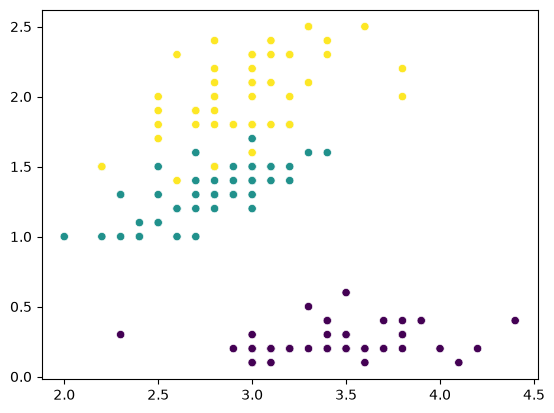

In [7]:
# Visualize the data as 4 features so cannot visualize here in scatter that's why
# we will take any 2 features. not perfect visualization 
sns.scatterplot(x=X[:, 1], y=X[:, 3], c=y)


In [8]:
# so Before finding Optimal K we need to scale our data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# apply elbow method to find K: as we know K value but for the sake of practice
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

<Axes: >

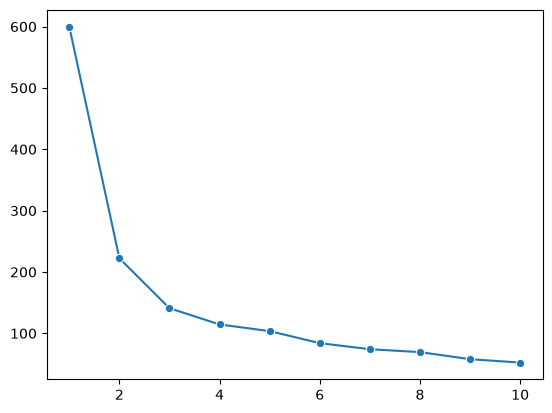

In [13]:
sns.lineplot(x=range(1,11), y=wcss, marker='o')

<Axes: >

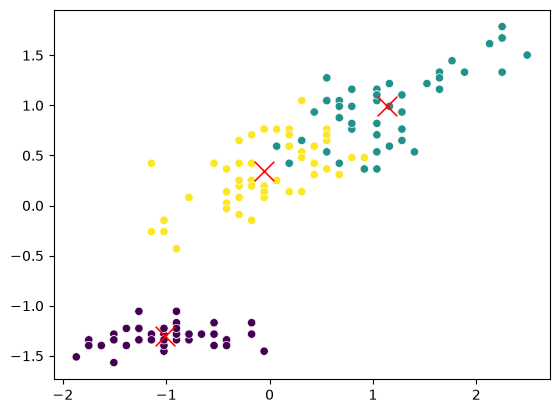

In [49]:
# as we find optimal k value which is k=3

kmeans = KMeans(n_clusters=3)
labels = kmeans.fit_predict(X_scaled)

sns.scatterplot(x=X_scaled[:,0], y=X_scaled[:,2], c=labels)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:,2], marker="x", c="red", s=200)

<Axes: >

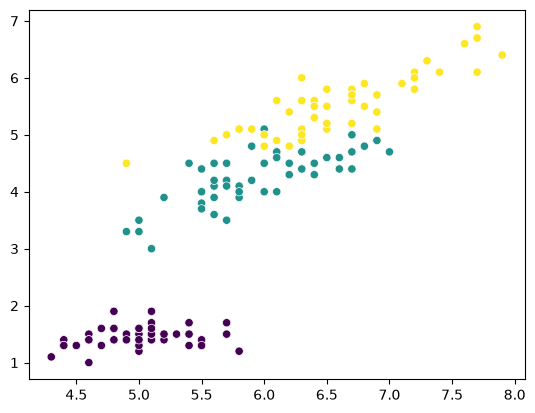

In [18]:
sns.scatterplot(x=X[:,0], y=X[:,2], c=y)

### Dimensionality Reduction using PCA:


In [24]:
# so Before finding Optimal K we need to scale our data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Now PCA implemenation

from sklearn.decomposition import PCA
pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

In [25]:
# here pass PCA Data
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(pca_data)
    wcss.append(kmeans.inertia_)

<Axes: >

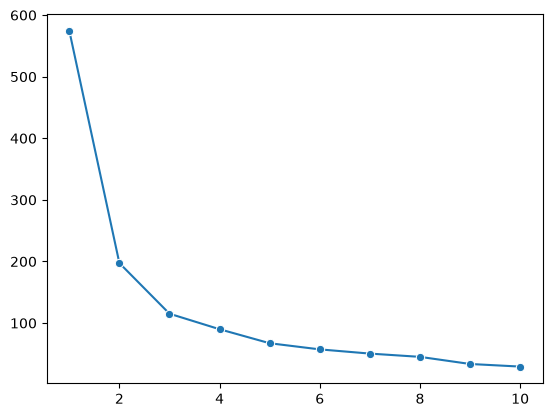

In [26]:
sns.lineplot(x=range(1,11), y=wcss, marker='o')

<Axes: >

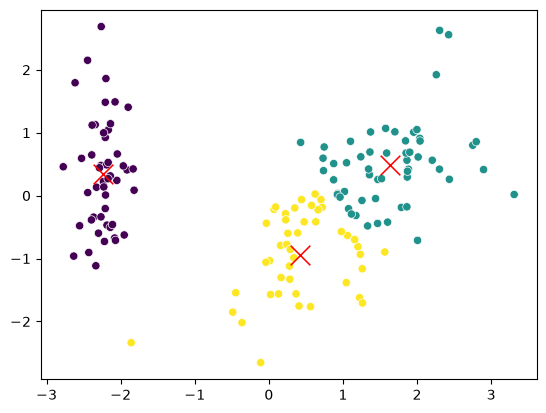

In [44]:
# KMeans

kmeans = KMeans(n_clusters=3, random_state=22)
labels = kmeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:,0], y=pca_data[:,1], c=labels)

sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], marker='x', c="red", s=200)